# Chapter 13 · Gaussian vectors: interactive demos

Companion to Chapter 13 of the notes [*Probability with Measure Theory*](https://gennaroalberto.github.io/probability-measure-theory/notes.pdf).
Each section draws a figure with default settings, then an **Explore** cell lets you move the parameters.
The sliders need a running kernel: open the notebook in
[Google Colab](https://colab.research.google.com/github/GennaroAlberto/probability-measure-theory/blob/main/code/notebooks/13-gaussian-vectors.ipynb)
or in Jupyter after `pip install -e "code[dev]"`.

In [1]:
# In Google Colab, this installs the course package from GitHub; elsewhere it does nothing.
import sys
if "google.colab" in sys.modules:
    %pip install -q "git+https://github.com/GennaroAlberto/probability-measure-theory#subdirectory=code"

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from ipywidgets import interact, IntSlider, FloatSlider, Dropdown

from probnotes.gaussian import (affine_image, bivariate_cov, cf_factorisation_defect, distance_to_support,
                                factor, gaussian_density, is_covariance, random_sign_sum_cdf, rank,
                                sample_mean_cov, sample_random_sign_pair, sample_sign_flip_pair,
                                sign_flip_covariance, sign_flip_root, support_basis, whiten)
from probnotes.style import COBALT, GOLD, GREY, INK, use_style

GREEN = "#1BAF7A"
use_style()


def ellipse(mu, C, p=0.9, n=200):
    # boundary of {y : (y - mu)^T C^{-1} (y - mu) <= r^2}, which holds probability p (chi^2(2) law)
    r = np.sqrt(stats.chi2.ppf(p, 2))
    th = np.linspace(0, 2 * np.pi, n)
    return np.asarray(mu)[:, None] + r * factor(C, "sqrt") @ np.vstack([np.cos(th), np.sin(th)])

## 1. One law, many square roots

A Gaussian vector is $\underline Y=A\underline X+\underline\mu$ with $\underline X$ standard (Definition 13.2), and its law
$\mathcal N_N(\underline\mu,C)$ depends on $A$ only through $C=AA^T$ (Proposition 13.5). Here $\underline X$ is a standard sample in
$\mathbb R^2$ (left) and $C$ has standard deviations $\sigma_1,\sigma_2$ and correlation $\rho$. The middle and right panels map
**the same** points through the symmetric square root of $C$ (used in the proof of Theorem 13.9) and through its Cholesky factor:
the clouds have the same law, with the same $90\%$ ellipse, but the three marked points land in different places. When
$|\rho|=1$ or a $\sigma_i=0$, $C$ is singular: the vector is degenerate and lives on the line $\operatorname{Im}C$ (Remark 13.11);
both factors still work.

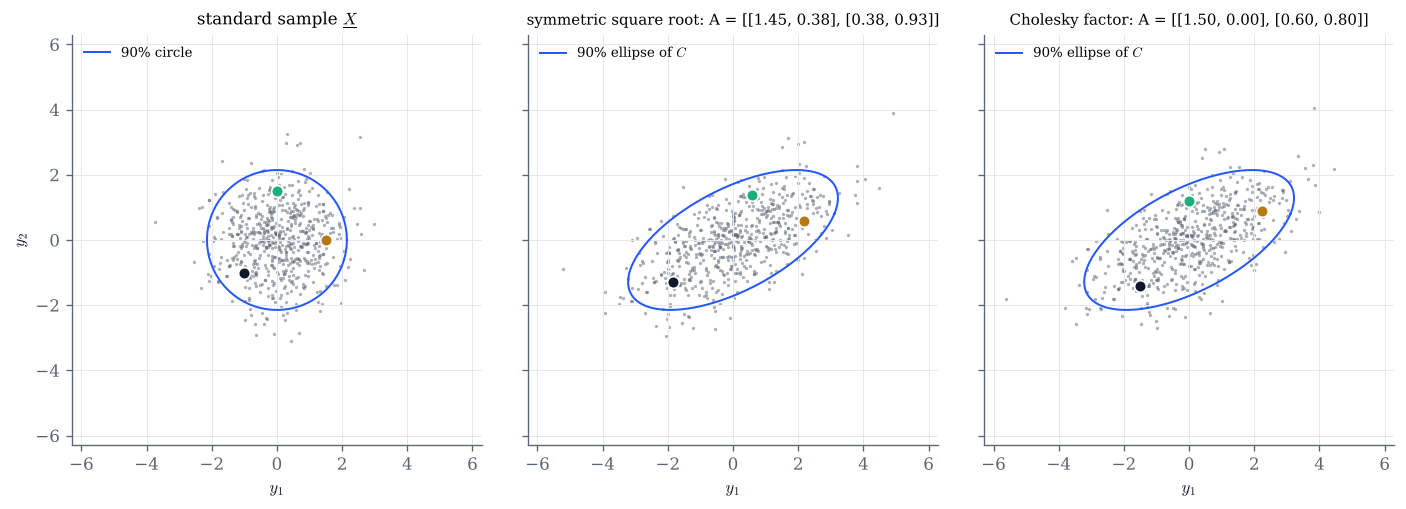

C = [[2.25, 0.9], [0.9, 1.0]],  det C = 1.4400,  rank 2
sample covariance of the middle cloud = [[2.267, 0.96], [0.96, 1.063]]


In [3]:
def roots_demo(s1=1.5, s2=1.0, rho=0.6, n=600, seed=2026):
    C = bivariate_cov(s1, s2, rho)
    rng = np.random.default_rng(seed)
    X = rng.standard_normal((n, 2))
    marks = np.array([[1.5, 0.0], [0.0, 1.5], [-1.0, -1.0]])
    fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharex=True, sharey=True)
    lim = 4.2 * max(1.0, s1, s2)
    axes[0].scatter(X[:, 0], X[:, 1], s=4, color=GREY, alpha=0.5, lw=0)
    axes[0].plot(*ellipse([0, 0], np.eye(2)), color=COBALT, lw=1.2, label="90% circle")
    axes[0].set_title(r"standard sample $\underline{X}$")
    for ax, method, name in ((axes[1], "sqrt", "symmetric square root"), (axes[2], "cholesky", "Cholesky factor")):
        A = factor(C, method)
        Y = X @ A.T
        ax.scatter(Y[:, 0], Y[:, 1], s=4, color=GREY, alpha=0.5, lw=0)
        if rank(C) == 2:
            ax.plot(*ellipse([0, 0], C), color=COBALT, lw=1.2, label="90% ellipse of $C$")
        else:
            U = support_basis(C)
            t = np.linspace(-2 * lim, 2 * lim, 2)
            if U.shape[1]:
                ax.plot(t * U[0, 0], t * U[1, 0], color=COBALT, lw=1.0, ls="--", label=r"Im $C$ (degenerate)")
        ax.set_title(f"{name}: A = [[{A[0,0]:.2f}, {A[0,1]:.2f}], [{A[1,0]:.2f}, {A[1,1]:.2f}]]", fontsize=9)
    for ax, M in zip(axes, (np.eye(2), factor(C, "sqrt"), factor(C, "cholesky"))):
        P = marks @ M.T
        for k, col in enumerate((GOLD, GREEN, INK)):
            ax.plot(*P[k], "o", color=col, ms=7, mec="white")
        ax.set(xlim=(-lim, lim), ylim=(-lim, lim), xlabel="$y_1$")
        ax.set_aspect("equal")
        ax.legend(loc="upper left", fontsize=8)
    axes[0].set_ylabel("$y_2$")
    fig.tight_layout()
    plt.show()
    S = sample_mean_cov(X @ factor(C, "sqrt").T)[1]
    print(f"C = {C.round(3).tolist()},  det C = {np.linalg.det(C):.4f},  rank {rank(C)}")
    print(f"sample covariance of the middle cloud = {S.round(3).tolist()}")

roots_demo()

In [4]:
# Explore: rho = +-1 gives a degenerate vector on a line; compare where the coloured points go.
interact(roots_demo,
         s1=FloatSlider(value=1.5, min=0.0, max=3.0, step=0.1, continuous_update=False, description="sigma 1"),
         s2=FloatSlider(value=1.0, min=0.0, max=3.0, step=0.1, continuous_update=False, description="sigma 2"),
         rho=FloatSlider(value=0.6, min=-1.0, max=1.0, step=0.05, continuous_update=False, description="rho"),
         n=IntSlider(value=600, min=50, max=5000, step=50, continuous_update=False, description="n"),
         seed=IntSlider(value=2026, min=0, max=3000, continuous_update=False, description="seed"));

## 2. Affine images

By Theorem 13.6, if $\underline Y\sim\mathcal N_2(\underline\mu,C)$ then $\underline U=B\underline Y+\underline\gamma\sim
\mathcal N_2(B\underline\mu+\underline\gamma,BCB^T)$. Here $\underline Y$ has the law of Example 13.12,
$C=\left(\begin{smallmatrix}2&1\\1&1\end{smallmatrix}\right)$. Choose $B$ and $\underline\gamma$: the right panel shows the
sample of $\underline U$ with the $90\%$ ellipse of the predicted law, and the printout compares $BCB^T$ with the sample
covariance. When $\det B=0$, $BCB^T$ is singular, and $\underline U$ collapses onto the line
$B\underline\mu+\underline\gamma+\operatorname{Im}(BCB^T)$.

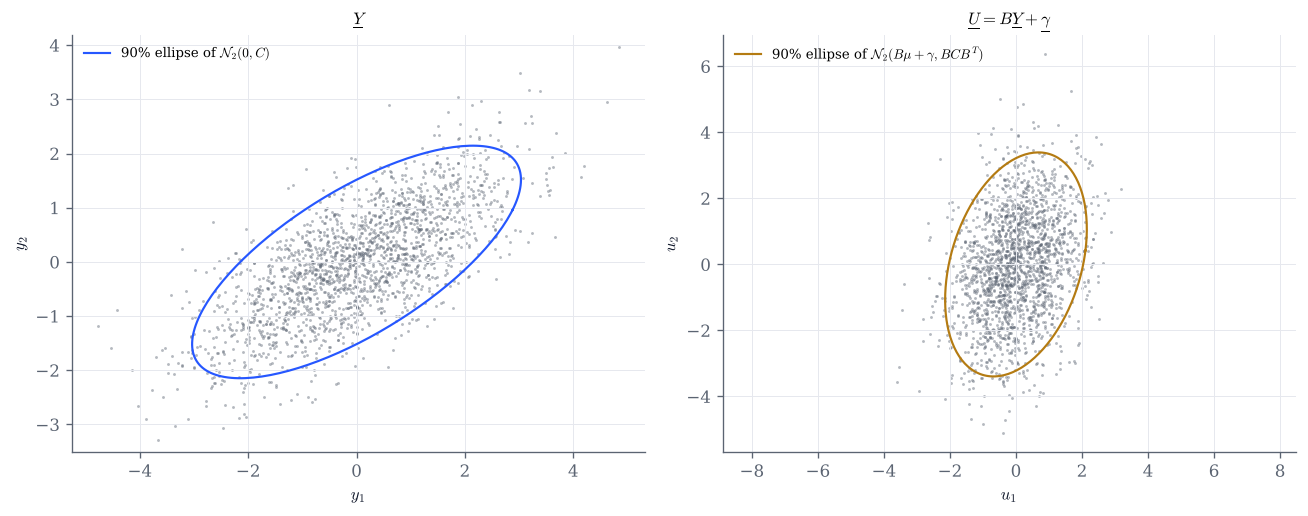

det B = +1.500   B C B^T = [[1.0, 0.5], [0.5, 2.5]]   rank 2
sample covariance of U = [[0.984, 0.464], [0.464, 2.581]]


In [5]:
C0, MU0 = np.array([[2.0, 1.0], [1.0, 1.0]]), np.zeros(2)

def affine_demo(b11=1.0, b12=-1.0, b21=0.5, b22=1.0, g1=0.0, g2=0.0, n=2000, seed=2026):
    B, gam = np.array([[b11, b12], [b21, b22]]), np.array([g1, g2])
    rng = np.random.default_rng(seed)
    Y = rng.standard_normal((n, 2)) @ factor(C0, "sqrt").T + MU0
    U = Y @ B.T + gam
    m, S = affine_image(MU0, C0, B, gam)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.4))
    a1.scatter(Y[:, 0], Y[:, 1], s=3, color=GREY, alpha=0.45, lw=0)
    a1.plot(*ellipse(MU0, C0), color=COBALT, lw=1.3, label=r"90% ellipse of $\mathcal{N}_2(0, C)$")
    a1.set(title=r"$\underline{Y}$", xlabel="$y_1$", ylabel="$y_2$")
    a2.scatter(U[:, 0], U[:, 1], s=3, color=GREY, alpha=0.45, lw=0)
    if rank(S) == 2:
        a2.plot(*ellipse(m, S), color=GOLD, lw=1.3, label=r"90% ellipse of $\mathcal{N}_2(B\mu+\gamma, BCB^T)$")
    elif rank(S) == 1:
        u = support_basis(S)[:, 0]
        t = np.array([-1, 1]) * 4 * np.sqrt(np.trace(S))
        a2.plot(m[0] + t * u[0], m[1] + t * u[1], color=GOLD, lw=1.0, ls="--", label="support line (degenerate)")
    else:
        a2.plot(*m, "o", color=GOLD, label="a single point")
    a2.set(title=r"$\underline{U}=B\underline{Y}+\underline{\gamma}$", xlabel="$u_1$", ylabel="$u_2$")
    for ax in (a1, a2):
        ax.set_aspect("equal", adjustable="datalim")
        ax.legend(loc="upper left", fontsize=8)
    fig.tight_layout()
    plt.show()
    print(f"det B = {np.linalg.det(B):+.3f}   B C B^T = {S.round(3).tolist()}   rank {rank(S)}")
    print(f"sample covariance of U = {sample_mean_cov(U)[1].round(3).tolist()}")
    if rank(S) < 2:
        print(f"largest distance of the sample from the support: {distance_to_support(U, m, S).max():.1e}")

affine_demo()

In [6]:
# Explore: make B singular (for instance b21 = 0.5 b11 and b22 = 0.5 b12) and watch the cloud collapse.
sl = dict(min=-2.0, max=2.0, step=0.1, continuous_update=False)
interact(affine_demo,
         b11=FloatSlider(value=1.0, description="b11", **sl), b12=FloatSlider(value=-1.0, description="b12", **sl),
         b21=FloatSlider(value=0.5, description="b21", **sl), b22=FloatSlider(value=1.0, description="b22", **sl),
         g1=FloatSlider(value=0.0, description="gamma 1", **sl), g2=FloatSlider(value=0.0, description="gamma 2", **sl),
         n=IntSlider(value=2000, min=100, max=20000, step=100, continuous_update=False, description="n"),
         seed=IntSlider(value=2026, min=0, max=3000, continuous_update=False, description="seed"));

## 3. Gaussian marginals that are not jointly Gaussian

Example 13.19: with $X\sim\mathcal N(0,1)$ and an independent random sign $Z$, $Y=ZX$ is again $\mathcal N(0,1)$, but $(X,Y)$ lives
on the two diagonals and $X+Y$ has an atom of mass $\frac12$ at $0$; so $(X,Y)$ is not a Gaussian vector. Exercise 13.5 builds
another pair: $Y=X$ where $|X|\le c$ and $Y=-X$ elsewhere. For $c=c^*\approx1.538$ the two are uncorrelated, yet dependent:
by Theorem 13.20 this is impossible for a Gaussian vector. The right panel shows $\operatorname{cov}(X,Y)$ as a function of $c$.
The printout gives the empirical characteristic-function defect of the independence criterion (Theorem 10.20), which is
of order $n^{-1/2}$ for independent variables: a value that stays away from $0$ as $n$ grows proves dependence (on a finite
grid the converse can fail).

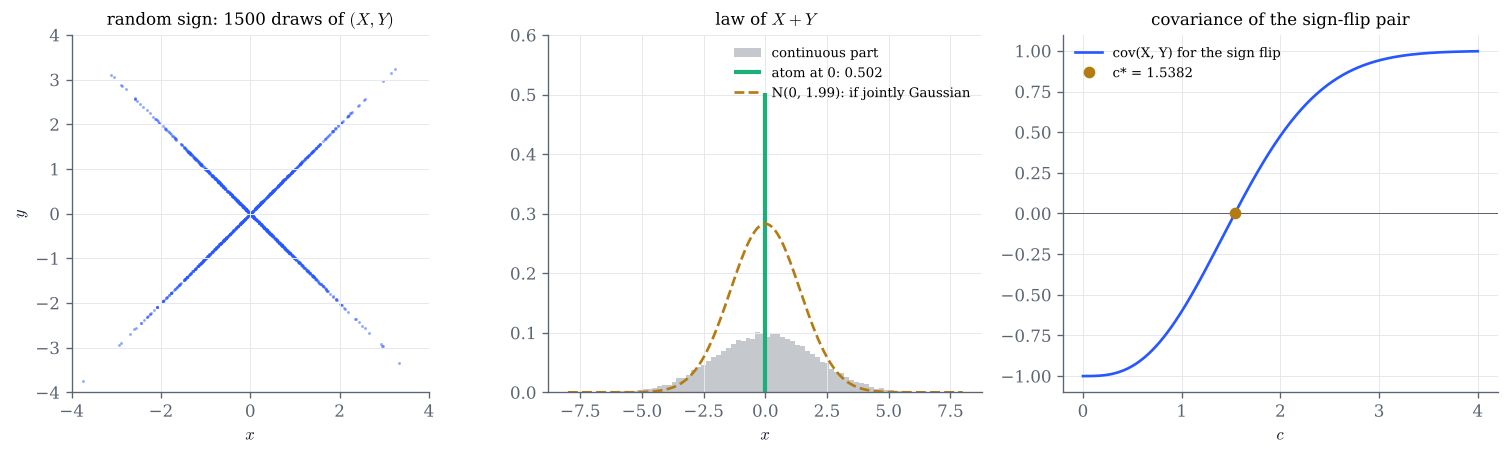

sample corr(X, Y) = -0.0029   P(X + Y = 0) ~ 0.5021   cf defect = 0.506  (independent pairs: about 0.014)


In [7]:
def marginals_demo(pair="random sign", c=1.538, n=50_000, seed=2026):
    if pair == "random sign":
        X, Y = sample_random_sign_pair(n, seed=seed)
    else:
        X, Y = sample_sign_flip_pair(n, c, seed=seed)
    S = X + Y
    p0 = np.mean(S == 0)
    fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(13, 3.9))
    a1.scatter(X[:1500], Y[:1500], s=3, color=COBALT, alpha=0.5, lw=0)
    a1.set(xlim=(-4, 4), ylim=(-4, 4), xlabel="$x$", ylabel="$y$", title=f"{pair}: 1500 draws of $(X, Y)$")
    a1.set_aspect("equal")
    cont = S[S != 0]
    bins = np.linspace(-8, 8, 81)
    a2.hist(cont, bins=bins, weights=np.full(cont.size, 1 / S.size / (bins[1] - bins[0])), color=GREY, alpha=0.35,
            label="continuous part")
    a2.vlines(0, 0, p0, color=GREEN, lw=2.5, label=f"atom at 0: {p0:.3f}")
    x = np.linspace(-8, 8, 400)
    v = np.var(S)
    a2.plot(x, stats.norm.pdf(x, scale=np.sqrt(v)), color=GOLD, ls="--", label=f"N(0, {v:.2f}): if jointly Gaussian")
    a2.set(xlabel="$x$", title="law of $X+Y$", ylim=(0, max(0.6, p0 + 0.05)))
    a2.legend(fontsize=8)
    cs = np.linspace(0, 4, 300)
    a3.plot(cs, sign_flip_covariance(cs), color=COBALT, label="cov(X, Y) for the sign flip")
    a3.axhline(0, color=GREY, lw=0.6)
    a3.plot([sign_flip_root()], [0], "o", color=GOLD, label=f"c* = {sign_flip_root():.4f}")
    if pair != "random sign":
        a3.plot([c], [sign_flip_covariance(c)], "s", color=GREEN, label=f"c = {c:.3f}")
    a3.set(xlabel="$c$", title="covariance of the sign-flip pair")
    a3.legend(fontsize=8)
    fig.tight_layout()
    plt.show()
    print(f"sample corr(X, Y) = {np.corrcoef(X, Y)[0, 1]:+.4f}   P(X + Y = 0) ~ {p0:.4f}   "
          f"cf defect = {cf_factorisation_defect(X[:20000], Y[:20000]):.3f}  "
          f"(independent pairs: about {2 / np.sqrt(20000):.3f})")

marginals_demo()

In [8]:
# Explore: for the sign flip, move c through c* = 1.538: the correlation changes sign, the dependence stays.
interact(marginals_demo,
         pair=Dropdown(options=["random sign", "sign flip"], value="random sign", description="pair"),
         c=FloatSlider(value=1.538, min=0.1, max=4.0, step=0.01, continuous_update=False, description="c"),
         n=IntSlider(value=50_000, min=2000, max=200_000, step=2000, continuous_update=False, description="n"),
         seed=IntSlider(value=2026, min=0, max=3000, continuous_update=False, description="seed"));

## 4. Whitening

The proof of Theorem 13.9 turns $\underline Y\sim\mathcal N_N(\underline\mu,C)$ into a standard vector
$\underline X=C^{-1/2}(\underline Y-\underline\mu)$. Any $A$ with $AA^T=C$ works, and two choices differ by an orthogonal map
(Exercise 13.9): below, the inverse symmetric square root ("ZCA") and the inverse Cholesky factor, applied to the same sample with
the true parameters, give clouds that differ by a rotation or reflection (follow the coloured points). With the *estimated*
mean and covariance, the whitened sample has sample covariance exactly $I_2$, whatever the law.

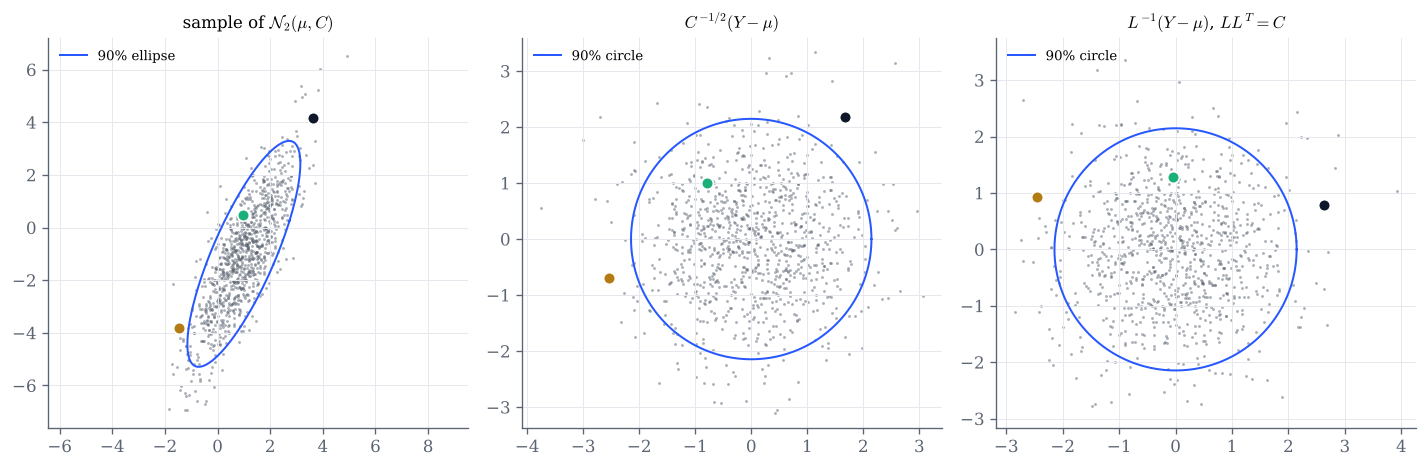

orthogonal matrix relating the two whitenings, Q = L^-1 C^1/2 = [[0.809, 0.588], [-0.588, 0.809]]
sample covariance, true parameters:       [[0.992, 0.009], [0.009, 1.031]]
sample covariance, estimated parameters:  [[1.0, -0.0], [-0.0, 1.0]]


In [9]:
def whitening_demo(rho=0.8, s2=2.0, n=1000, seed=2026):
    mu, C = np.array([1.0, -1.0]), bivariate_cov(1.0, s2, rho)
    rng = np.random.default_rng(seed)
    Y = rng.standard_normal((n, 2)) @ factor(C, "sqrt").T + mu
    Wz, Wc = whiten(Y, mu, C, "zca"), whiten(Y, mu, C, "cholesky")
    idx = np.argsort(Y[:, 0])[[5, n // 2, n - 6]]          # three points, from left to right
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    for ax, Z, title in ((axes[0], Y, r"sample of $\mathcal{N}_2(\mu, C)$"), (axes[1], Wz, r"$C^{-1/2}(Y-\mu)$"),
                         (axes[2], Wc, r"$L^{-1}(Y-\mu)$, $LL^T=C$")):
        ax.scatter(Z[:, 0], Z[:, 1], s=3, color=GREY, alpha=0.5, lw=0)
        for k, col in zip(idx, (GOLD, GREEN, INK)):
            ax.plot(*Z[k], "o", color=col, ms=7, mec="white")
        ax.set_title(title)
        ax.set_aspect("equal", adjustable="datalim")
    for ax in axes[1:]:
        ax.plot(*ellipse([0, 0], np.eye(2)), color=COBALT, lw=1.2, label="90% circle")
        ax.legend(loc="upper left", fontsize=8)
    axes[0].plot(*ellipse(mu, C), color=COBALT, lw=1.2, label="90% ellipse")
    axes[0].legend(loc="upper left", fontsize=8)
    fig.tight_layout()
    plt.show()
    Q = np.linalg.solve(np.linalg.cholesky(C), factor(C, "sqrt"))
    print("orthogonal matrix relating the two whitenings, Q = L^-1 C^1/2 =", Q.round(3).tolist())
    print("sample covariance, true parameters:      ", sample_mean_cov(Wz)[1].round(3).tolist())
    print("sample covariance, estimated parameters: ", sample_mean_cov(whiten(Y))[1].round(12).tolist())

whitening_demo()

In [10]:
# Explore: strong correlation makes the Cholesky and ZCA whitenings differ by a larger rotation.
interact(whitening_demo,
         rho=FloatSlider(value=0.8, min=-0.98, max=0.98, step=0.02, continuous_update=False, description="rho"),
         s2=FloatSlider(value=2.0, min=0.2, max=4.0, step=0.1, continuous_update=False, description="sigma 2"),
         n=IntSlider(value=1000, min=50, max=20000, step=50, continuous_update=False, description="n"),
         seed=IntSlider(value=2026, min=0, max=3000, continuous_update=False, description="seed"));

## Things to try

- In section 1, set $\rho=1$: which line do the points lie on, and why is it the same for both factors? Now set $\sigma_2=0$ with $\rho=0.6$: what is $C$ then?
- In section 1, set $\rho=0$: the symmetric square root and the Cholesky factor coincide. Why?
- In section 2, take $B=\left(\begin{smallmatrix}1&-1\\1&1\end{smallmatrix}\right)$: are $U_1=Y_1-Y_2$ and $U_2=Y_1+Y_2$ independent? Compute $BCB^T$ by hand and use Theorem 13.20.
- In section 2, find a $B$ with $\det B\ne0$ for which $BCB^T=I_2$: this is a whitening (section 4).
- In section 3, with the random sign, the atom of $X+Y$ stays at $\frac12$ for every $n$; with the sign flip, check that it equals $2(1-\Phi(c))$.
- In section 4, set $\rho$ close to $\pm1$ and a small $n$: the estimated whitening still gives exactly the identity, but compare the clouds.